In [1]:
import argparse
from rclpy.serialization import deserialize_message
from rosidl_runtime_py.utilities import get_message
from std_msgs.msg import String
from geometry_msgs.msg import PoseStamped
import rosbag2_py
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

from control_msgs.msg import DynamicJointState
from builtin_interfaces.msg import Time
from std_msgs.msg import Header
from scipy.spatial.transform import Rotation as R

import math
from math import pi

In [2]:
def get_metadata(input_bag: str):
    # Use to get topic names and counts.
    reader = rosbag2_py.SequentialReader()
    reader.open(
        rosbag2_py.StorageOptions(uri=input_bag, storage_id="mcap"),
        rosbag2_py.ConverterOptions(
            input_serialization_format="cdr", output_serialization_format="cdr"
        ),
    )
    return reader.get_metadata()

def read_messages(input_bag: str):
    # Use to iterate through data.
    reader = rosbag2_py.SequentialReader()
    reader.open(
        rosbag2_py.StorageOptions(uri=input_bag, storage_id="mcap"),
        rosbag2_py.ConverterOptions(
            input_serialization_format="cdr", output_serialization_format="cdr"
        ),
    )
#     print(reader.get_metadata())

    topic_types = reader.get_all_topics_and_types()

    def typename(topic_name):
        for topic_type in topic_types:
            if topic_type.name == topic_name:
                return topic_type.type
        raise ValueError(f"topic {topic_name} not in bag")

    while reader.has_next():
        topic, data, timestamp = reader.read_next()
        msg_type = get_message(typename(topic))
        msg = deserialize_message(data, msg_type)
        yield topic, msg, timestamp
    del reader

In [3]:
bag_path = "../../logging/2025_2_16_rosbags/2025_2_16__17_35_4130RPMback_60RPMfront_v2.bag/2025_2_16__17_35_4130RPMback_60RPMfront_v2.bag_0.mcap"
metadata = get_metadata(bag_path)

# Use this to find out topics and their message counts. 
topics = {name.topic_metadata.name : name.message_count for name in metadata.topics_with_message_count}

# Print out to check what's in the ROSbag.
for topic,count in topics.items():
    print(topic, count)

/odom_in_vicon_frame 0
/dynamic_joint_states 1621
/rb_slip_controller/transition_event 0
/rb_slip_controller/cmd_vel 7091
/joint_state_broadcaster/transition_event 0
/joint_states 1622
/rb_slip_controller/odom 1616
/tf 2434
/robot_description 1
/tf_static 2
/diagnostics 59
/joy 880
/rosout 1684
/right_motor_currents 9366
/pico_imu 7412
/parameter_events 1
/left_motor_currents 9694
/rb/cmd_vel 0
/events/write_split 0
/vrpn_mocap/wand_test/accel 0
/vrpn_mocap/rb1/twist 11912
/vrpn_mocap/rb1/accel 11913
/vrpn_mocap/rb1/pose 11912
/vrpn_mocap/wand_test/pose 0
/vrpn_mocap/wand_test/twist 0


In [4]:
def get_header_stamp(msg: Time):
    # Helper function to quickly get the sec and nanosec components for a ROS2 Time object.
    sec = msg.sec
    nanosec = msg.nanosec
    return (sec, nanosec)

def get_stamp_bag_epoch(header, bag_epoch_sec, bag_epoch_nsec):
    # Offset the stamp of a message by the sec,nanosec of the bag epoch.
    # This will be the stamp of the first stamped message in the rosbag.
    sec = header.stamp.sec - bag_epoch_sec
    nsec = header.stamp.nanosec - bag_epoch_nanosec
    return float((sec * 1e9) + nsec)

In [5]:
joint_names = ['fr_wheel_joint', 'br_wheel_joint', 'fl_wheel_joint', 'bl_wheel_joint']
vicon_pose_vars = ['x','y','z','quat_x','quat_y','quat_z','quat_w']
left_current_vars = ['front','back']
right_current_vars = ['front','back']
imu_fields = ['ang_vel_x', 'ang_vel_y', 'ang_vel_z', 'lin_vel_x', 'lin_vel_y', 'lin_vel_z']

def make_data_structs():
    encoder_data = {
        'names' : joint_names,
        'index' : 0,
        'stamp_nsec': np.zeros(1621, dtype=np.float64),
        'stamp': np.zeros(1621, dtype=np.float64),
        'encoder_count' : np.zeros((len(joint_names),1621), dtype=np.int64)
    }
    
    # vrpn_mocap_rb1_pose = {k: np.zeros(11912, dtype=np.float64) for k in vicon_pose_vars}
    vrpn_mocap_rb1_data={
        'index' : 0,
        'stamp_nsec': np.zeros(11912, dtype=np.float64),
        'stamp': np.zeros(11912, dtype=np.float64),
        'pose' : np.zeros((len(vicon_pose_vars),11912), dtype=np.float64)
    }
    
    left_current_data = {
        'index' : 0,
        'stamp_nsec': np.zeros(9694, dtype=np.float64),
        'stamp': np.zeros(9694, dtype=np.float64),
        'currents' : np.zeros((2,9694), dtype=np.float64) # Front,back
    }
    
    right_current_data = {
        'index' : 0,
        'stamp_nsec': np.zeros(9366, dtype=np.float64),
        'stamp': np.zeros(9366, dtype=np.float64),
        'currents' : np.zeros((2,9366), dtype=np.float64)
    }

    imu_data = {
        'index' : 0,
        'stamp_nsec': np.zeros(7412, dtype=np.float64),
        'stamp': np.zeros(7412, dtype=np.float64),
        'fields' : imu_fields,
        'data' : np.zeros((len(imu_fields),7412), dtype=np.float64)
    }

    return encoder_data, vrpn_mocap_rb1_data, left_current_data, right_current_data, imu_data


In [6]:
first_message = None
bag_epoch_sec = None
bag_epoch_nanosec = None
   
msgs = read_messages(bag_path)

encoder_data, vrpn_mocap_rb1_data, left_current_data, right_current_data, imu_data = make_data_structs()

for topic, msg, _ in msgs:
    # Set rosbag epoch time.
    if first_message == None and hasattr(msg, "header"): # Use for relative time calc.
        first_message = msg
        print("First timestamped message is on ", topic)
        bag_epoch_sec = first_message.header.stamp.sec
        bag_epoch_nanosec = first_message.header.stamp.nanosec
        print("Rosbag epoch time is: ", bag_epoch_sec,"sec, \t", bag_epoch_nanosec/1e9, "nanosec\n\n\n")
    
    elif topic == '/dynamic_joint_states':
        idx = encoder_data['index']
        encoder_data['index'] += 1
        encoder_data['stamp_nsec'][idx] = get_stamp_bag_epoch(msg.header, bag_epoch_sec, bag_epoch_nanosec)
        encoder_data['stamp'] = encoder_data['stamp_nsec'] / 1e9
        
        # Name order must match that of the message for this to work.
        encoder_data['encoder_count'][:,idx] = [interface_values.values[2] for interface_values in msg.interface_values]

    elif topic == '/vrpn_mocap/rb1/pose':
        idx = vrpn_mocap_rb1_data['index']
        vrpn_mocap_rb1_data['index'] += 1
        vrpn_mocap_rb1_data['stamp_nsec'][idx] = get_stamp_bag_epoch(msg.header, bag_epoch_sec, bag_epoch_nanosec)
        vrpn_mocap_rb1_data['stamp'] = vrpn_mocap_rb1_data['stamp_nsec'] / 1e9

        vrpn_mocap_rb1_data['pose'][:,idx] = [
        msg.pose.position.x, msg.pose.position.y, msg.pose.position.z,
        msg.pose.orientation.x, msg.pose.orientation.y, msg.pose.orientation.z, msg.pose.orientation.w
    ]

    elif topic == '/left_motor_currents':
        idx = left_current_data['index']
        left_current_data['index'] += 1
        left_current_data['stamp_nsec'][idx] = get_stamp_bag_epoch(msg.header, bag_epoch_sec, bag_epoch_nanosec)
        left_current_data['stamp'] = left_current_data['stamp_nsec'] / 1e9
        
        # Invert left-front and back-right TODO fix this in hardware.
        left_current_data['currents'][:, idx] = [-1 * msg.data[0], msg.data[1]]

    elif topic == '/right_motor_currents':
        idx = right_current_data['index']
        right_current_data['index'] += 1
        right_current_data['stamp_nsec'][idx] = get_stamp_bag_epoch(msg.header, bag_epoch_sec, bag_epoch_nanosec)
        right_current_data['stamp'] = right_current_data['stamp_nsec'] / 1e9
        
        # Invert left-front and back-right TODO fix this in hardware.
        right_current_data['currents'][:, idx] = [msg.data[0], -1 * msg.data[1]]

    elif topic == '/pico_imu':
        idx = imu_data['index']
        imu_data['index'] += 1
        imu_data['stamp_nsec'][idx] = get_stamp_bag_epoch(msg.header, bag_epoch_sec, bag_epoch_nanosec)
        imu_data['stamp'] = imu_data['stamp_nsec'] / 1e9

        imu_data['data'][:, idx] = [msg.angular_velocity.x, msg.angular_velocity.y, msg.angular_velocity.z,
                            msg.linear_acceleration.x, msg.linear_acceleration.y, msg.linear_acceleration.z
                           ]



print(imu_data)

First timestamped message is on  /right_motor_currents
Rosbag epoch time is:  1739745341 sec, 	 0.710431517 nanosec



{'index': 7412, 'stamp_nsec': array([-2.22861600e+06,  5.85470700e+06,  1.38903400e+07, ...,
        6.01967142e+10,  6.02047770e+10,  6.02125459e+10], shape=(7412,)), 'stamp': array([-2.22861600e-03,  5.85470700e-03,  1.38903400e-02, ...,
        6.01967142e+01,  6.02047770e+01,  6.02125459e+01], shape=(7412,)), 'fields': ['ang_vel_x', 'ang_vel_y', 'ang_vel_z', 'lin_vel_x', 'lin_vel_y', 'lin_vel_z'], 'data': array([[-5.93412202e-03, -2.09439592e-03, -1.74533005e-03, ...,
        -1.39626395e-03, -3.49065987e-04, -1.74533005e-03],
       [ 1.74533005e-03,  3.49066011e-03,  4.88692382e-03, ...,
        -1.74533005e-03,  3.49065987e-04,  3.49065987e-04],
       [-2.44346191e-03,  4.53785807e-03,  0.00000000e+00, ...,
        -1.74533005e-03, -2.09439592e-03, -2.44346191e-03],
       [ 2.42714584e-01,  2.25552946e-01,  2.30456278e-01, ...,
         1.71616375e-01,  1.5935

In [7]:
def reset_encoders(encoder_data):
    """ Shift all encoder values to start at zero. Look at first set of encoder vals and subtract from 
    every encoder count in array.
    """
    print("start count ",encoder_data['encoder_count'][:,0])
    print("end count ",encoder_data['encoder_count'][:,-1])
    
    start_encoder_vals = encoder_data['encoder_count'][:,0]
    return encoder_data['encoder_count'] - start_encoder_vals.reshape(-1,1)

start count  [ 53959 -53322  41635 -36766]
end count  [108769 -30627  96957  -9538]
Min time step: 0.032966477999998745
Max time step: 0.04822399699999913
Mean time step: 0.03640801243950617
Max stamp: 60.218296028 sec
Max angle difference (radians): 0.2898675482844393


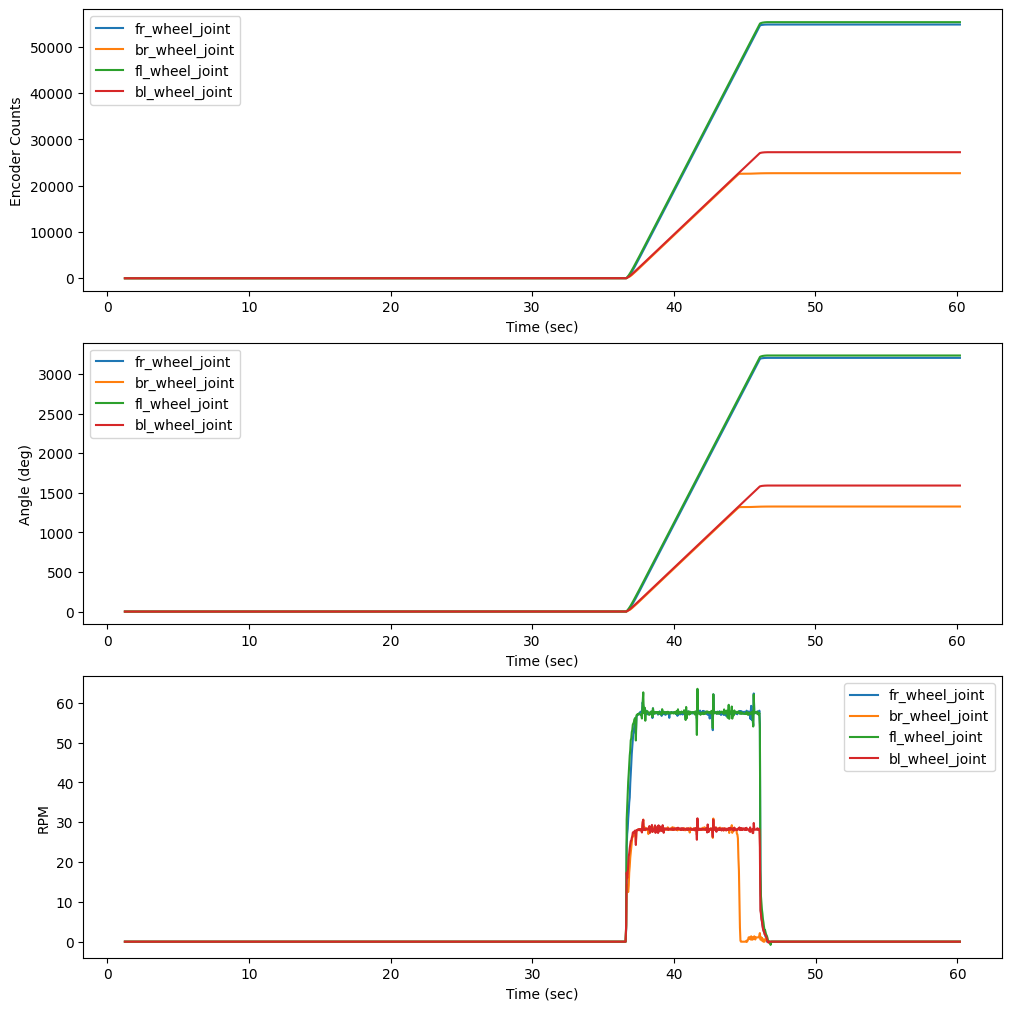

In [8]:
# Examine the encoder data. Convert to wheel angles.

# Reset encoder counts to zero.
encoder_data['encoder_count'] = reset_encoders(encoder_data)

# TODO Do we get counts or pulses?
PPR = 1539
CPR = PPR * 4
# Compute wheel angles in RAD.
encoder_data["wheel_angle"] = (encoder_data["encoder_count"] / CPR) * (2 * np.pi)

# Wheel angles in DEG.
encoder_data["wheel_angle_deg"] = (encoder_data["encoder_count"] / CPR) * 360.0

# Rough angular vel approx.
time_diff = np.diff(encoder_data["stamp"])  # Shape: (N-1,)
print("Min time step:", np.min(time_diff))
print("Max time step:", np.max(time_diff))
print("Mean time step:", np.mean(time_diff))
print("Max stamp:", np.max(encoder_data['stamp']), "sec")

angle_diff = np.diff(encoder_data["wheel_angle"], axis=1)  # Shape: (4, N-1)
print("Max angle difference (radians):", np.max(angle_diff))


# Slope at each time stamp.
encoder_data["wheel_velocity"] = angle_diff / time_diff  # Shape: (4, N-1)
encoder_data["wheel_velocity_rpm"] = encoder_data["wheel_velocity"] * (60 / (2*pi)) # Get in RPM as well.

# Remove last item from time stamp to match -1 size of the differentiated vector.
time_midpoints = encoder_data["stamp"][:-1]  # Same length as np.diff result


fig, ax = plt.subplots(3, figsize=(10,10), constrained_layout=True)
[a.set_xlabel("Time (sec)") for a in ax]

# Encoder counts.
ax[0].plot(np.tile(encoder_data['stamp'],(4,1)).T, encoder_data['encoder_count'].T) #matplot expects column data.
ax[0].legend(joint_names)
ax[0].set_ylabel("Encoder Counts")

# Wheel angle.
ax[1].plot(np.tile(encoder_data['stamp'],(4,1)).T, encoder_data['wheel_angle_deg'].T)
ax[1].legend(joint_names)
ax[1].set_ylabel("Angle (deg)")

# Wheel angular vel.
ax[2].plot(np.tile(time_midpoints, (4, 1)).T, encoder_data["wheel_velocity_rpm"].T)
ax[2].legend(joint_names)
ax[2].set_ylabel("RPM")

plt.show()

Min time step: 4.153000000073348e-05
Max time step: 0.229786981
Mean time step: 0.005025622890437412
Max stamp: 60.194394178 sec


Text(0.5, 1.0, 'Angular Velocity')

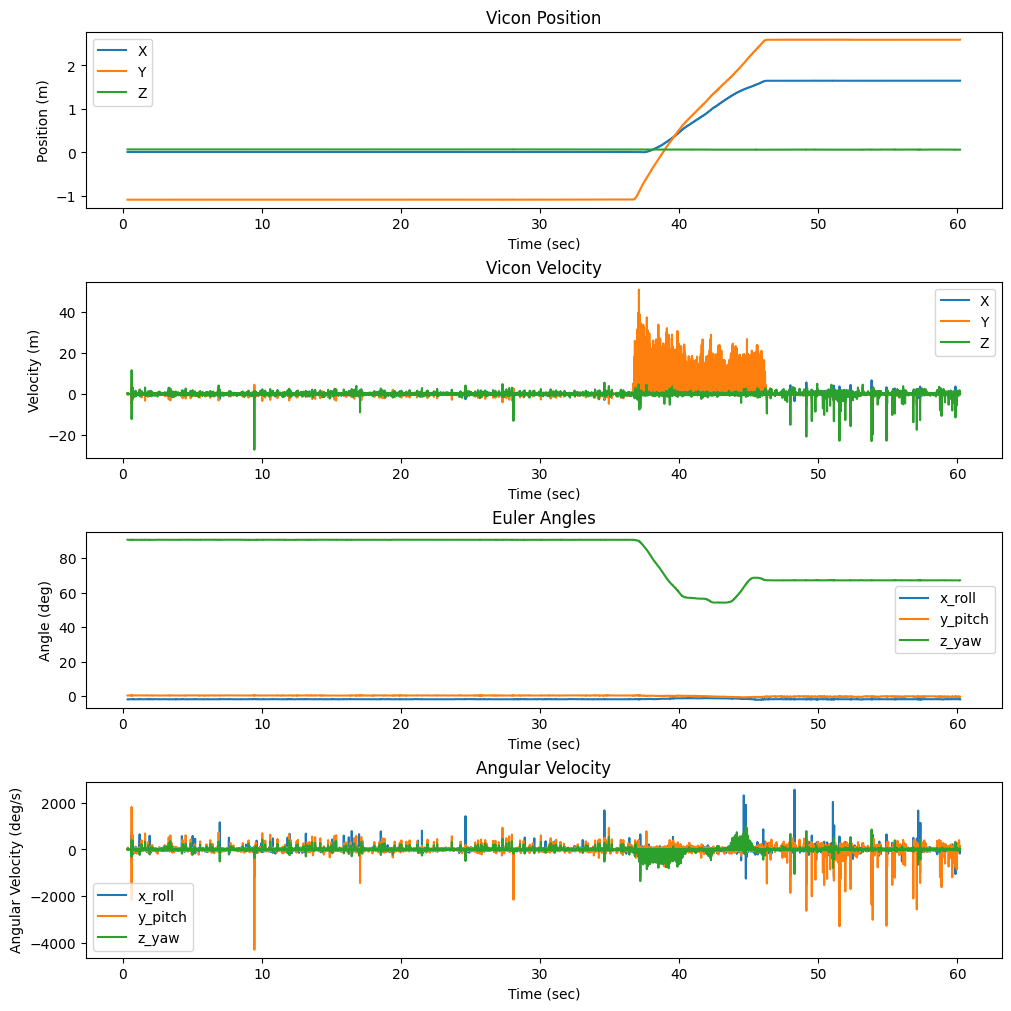

In [9]:
# Look at vicon data.
time_diff = np.diff(vrpn_mocap_rb1_data["stamp"])  # Shape: (N-1,)
print("Min time step:", np.min(time_diff))
print("Max time step:", np.max(time_diff))
print("Mean time step:", np.mean(time_diff))
print("Max stamp:", np.max(vrpn_mocap_rb1_data["stamp"]), "sec")

# Extract position and quaternion data.
position = vrpn_mocap_rb1_data["pose"][:3, :]  # X, Y, Z
quaternions = vrpn_mocap_rb1_data["pose"][3:, :].T  # Quaternion (N, 4)

# Euler angles from quaternions.
euler_angles = R.from_quat(quaternions).as_euler('xyz', degrees=True).T
vrpn_mocap_rb1_data["euler_angles"] = euler_angles

# Compute time step position differences.
position_diff = np.diff(position, axis=1)  # ΔX, ΔY, ΔZ

# Compute approximate velocity.
vrpn_mocap_rb1_data["velocity"] = (position_diff / time_diff)
time_midpoints = vrpn_mocap_rb1_data["stamp"][:-1]  # Use this to plot vel data?

# Compute time step euler angle differences
euler_angle_diff = np.diff(euler_angles, axis=1)

# Compute angular velocity.
vrpn_mocap_rb1_data["angular_velocity"] = euler_angle_diff / time_diff 

# Remove last timestamp to align with velocity data.
time_midpoints = vrpn_mocap_rb1_data["stamp"][:-1]




fig, ax = plt.subplots(4, figsize=(10, 10), constrained_layout=True)
[a.set_xlabel("Time (sec)") for a in ax]

# Linear pos.
ax[0].plot(vrpn_mocap_rb1_data["stamp"], position.T)
ax[0].legend(["X", "Y", "Z"])
ax[0].set_ylabel("Position (m)")
ax[0].set_title("Vicon Position")

# Linear velocity.
ax[1].plot(time_midpoints, vrpn_mocap_rb1_data["velocity"].T)
ax[1].legend(["X", "Y", "Z"])
ax[1].set_ylabel("Velocity (m)")
ax[1].set_title("Vicon Velocity")

# Euler angles
ax[2].plot(vrpn_mocap_rb1_data["stamp"], euler_angles.T)
ax[2].legend(["x_roll", "y_pitch", "z_yaw"])
ax[2].set_ylabel("Angle (deg)")
ax[2].set_title("Euler Angles")

# Angular Vel (deg/s)
ax[3].plot(time_midpoints, vrpn_mocap_rb1_data["angular_velocity"].T)
ax[3].legend(["x_roll", "y_pitch", "z_yaw"])
ax[3].set_ylabel("Angular Velocity (deg/s)")
ax[3].set_title("Angular Velocity")

In [10]:
print(left_current_data['currents'].shape)
print(left_current_data['stamp'].shape)

(2, 9694)
(9694,)


(2, 9694)


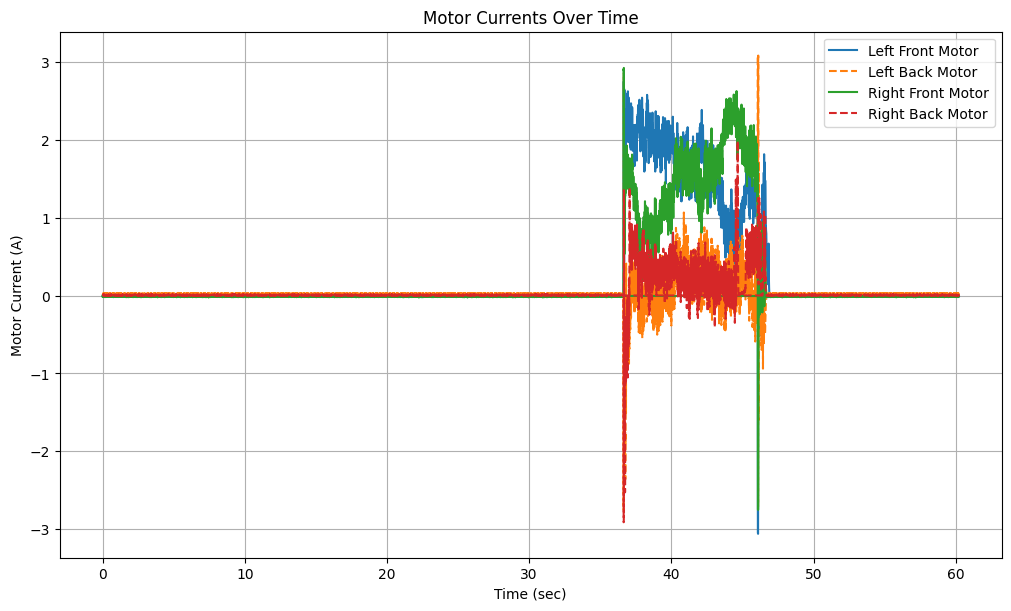

In [11]:
fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
print(left_current_data['currents'].shape)

# Plot left motor currents
ax.plot(left_current_data["stamp"], left_current_data["currents"][0,:], label="Left Front Motor", linestyle="-")
ax.plot(left_current_data["stamp"], left_current_data["currents"][1,:], label="Left Back Motor", linestyle="--")


ax.plot(right_current_data["stamp"], right_current_data["currents"][0,:], label="Right Front Motor", linestyle="-")
ax.plot(right_current_data["stamp"], right_current_data["currents"][1,:], label="Right Back Motor", linestyle="--")

ax.set_xlabel("Time (sec)")
ax.set_ylabel("Motor Current (A)")
ax.set_title("Motor Currents Over Time")
ax.legend()
ax.grid(True)

plt.show()


(6, 7412)


[Text(0.5, 1.0, 'IMU Angular Velocity'),
 Text(0.5, 1.0, 'IMU Linear Acceleration')]

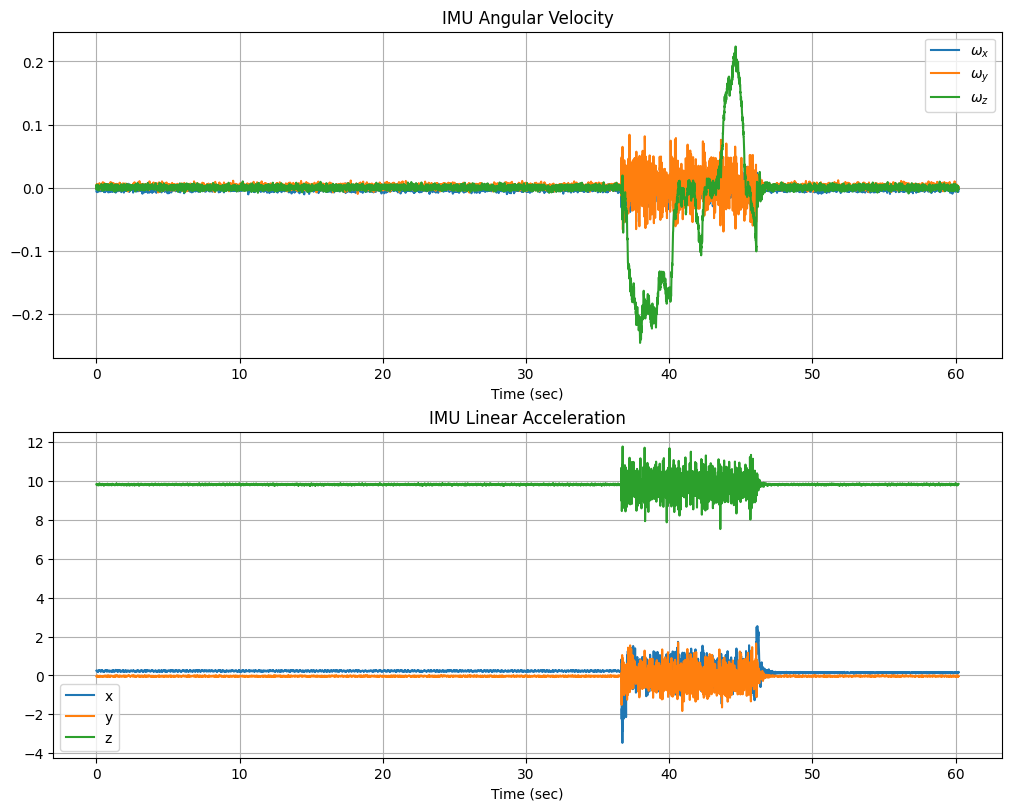

In [12]:
print(imu_data['data'].shape)

imu_angular_velocity = imu_data["data"][:3,:]  # (3,N)
imu_linear_acceleration = imu_data["data"][3:,:] # (3,N)

fig, ax = plt.subplots(2, figsize=(10, 8), constrained_layout=True)

# Titles for subplots.
titles = ["IMU Angular Velocity", "IMU Linear Acceleration"]
y_labels = ["Angular Velocity (rad/s)", "Linear Acceleration (m/s²)"]

# IMU field labels.
imu_labels = [["$\\omega_{x}$", "$\\omega_{y}$", "$\\omega_{z}$"], ["x", "y", "z"]]

[ax[i].plot(imu_data["stamp"], imu_data_filtered[j], label=imu_labels[i][j])
 for i, imu_data_filtered in enumerate([imu_angular_velocity, imu_linear_acceleration])
 for j in range(3)]


[ax[i].legend() or a[i].set_ylabel(y_labels[i]) or a[i].set_title(titles[i]) for i in range(2)]
[ax[i].set_xlabel("Time (sec)") for i in range(2)]
[ax[i].grid(True) for i in range(2)]
[ax[i].set_title(title) for i, title in enumerate(titles)]
